<a href="https://colab.research.google.com/github/MSGamgee85/MSGamgee85/blob/main/VaR_Monte_Carlo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![Google Colab](https://img.shields.io/badge/Google%20Colab-%23F9A825.svg?style=for-the-badge&logo=googlecolab&logoColor=black) ![NumPy](https://img.shields.io/badge/numpy-%23013243.svg?style=for-the-badge&logo=numpy&logoColor=white) ![Pandas](https://img.shields.io/badge/Pandas-%23150458.svg?style=for-the-badge&logo=pandas&logoColor=white) ![GitHub](https://img.shields.io/badge/github-%23121011.svg?style=for-the-badge&logo=github&logoColor=white)

---

## **Value at Risk (VaR) com simulação de Monte Carlo**

---

*Value at Risk (VaR)* representa a **perda máxima** de uma carteira de ativos para um dado **nível de confiança**. Essa medida foi desenvolvida em meados da década de 1990 por analistas do banco norte-americano J. P. Morgan como uma forma de sintetizar em um único número todas as informações de risco devido às exposições da instituição financeira e, assim, facilitar o processo de tomada de decisão.

<br>

---

**Definição**: Seja X uma *variável aleatória* que representa o **ganho ou perda** de um <u>ativo financeiro</u>, onde as perdas são valores negativos e os ganhos são valores positivos.

O VaR para um *nível de confiança* $\sf \alpha \in (0,1)$ é o menor número $\sf y$ tal que a probabilidade $\sf Y = P(-X)$ não excede $\sf y$ em pelo menos $\sf 1 - \alpha$. Em outras palavras, $\sf VaR_{\alpha}(X)$ é o $\sf (1 - \alpha)$ quantil de $\sf Y$

---


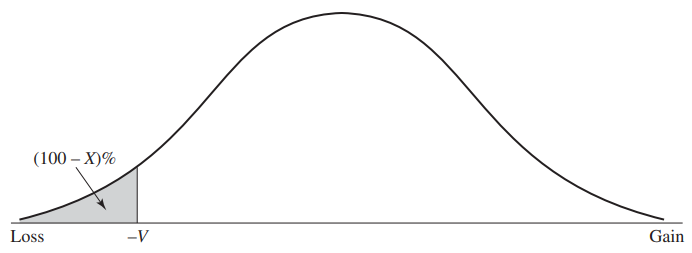


---

**Figura 1**. Cálculo do VaR através da distribuição de probabilidade de ganhos e perdas de um portfólio. Crédito da imagem: Hull, p. 235 (2023).



<br>

A definição acima não especifica como a função de distribuição de probabilidade de X é estimada; por outro lado, a estimativa para o VaR pode ser feita através de **modelos paramétricos** (como *EWMA* ou *ARCH-GARCH*) ou **não paramétricos** (*Monte Carlo*). $\blacksquare$

---
<small> <b>Obs.:</b> na prática, Monte Carlo é um método de simulação que utiliza amostras aleatórias para estimar resultados. A distribuição de dados, contudo, pode conter parâmetros como média e variância, mas a técnica em si é não paramétrica. </small>

<br>


Neste notebook vamos calcular o Value at Risk (VaR) para uma carteira de investimentos fictícia utilizando o método de Monte Carlo.

Para uma breve introdução sobre o método e exemplos de aplicações sugerimos conferir antes este [link](https://colab.research.google.com/drive/1b9Oq81Kb5dNku-XUXNj-KAfKCDT1bjce?usp=sharing) .

<br>

## **Referências**

---
Hull, J. C. **Risk Management and Financial Institutions**. John Wiley & Sons. 2023

Wikipedia. **Value at risk**. Disponível em: < https://en.wikipedia.org/wiki/Value_at_risk > . Acesso em: 18 nov. 2026

## **Configuração do ambiente**
---

In [68]:
# -- Bibliotecas utilizadas --
import numpy as np                # funções matemáticas e operações com array [vetores e matrizes]
import matplotlib.pyplot as plt   # geração e visualização de gráficos
import pandas as pd               # estruturas tabulares de organização e análise de dados

## **1. Definição de Parâmetros do Modelo**
---


In [69]:
# -- Configurações iniciais --
np.random.seed(42)              # define semente aleatória para reprodução de cenários

# Parâmetros da carteira e do mercado
valor_portfolio = 10000         # R$ 10000,00
retorno_medio = 0.0005          # Retorno esperado de 0.05% ao dia
volatilidade = 0.01             # Volatilidade de 1.0% ao dia

# Parâmetros da simulação
num_simulacoes = 10000
nivel_confianca = 0.95          # α = 95%

## **2. Execução da Simulação de Monte Carlo**
---


In [70]:
# -- Simulação de Monte Carlo --
retornos_simulados = np.random.normal(retorno_medio, volatilidade, num_simulacoes)  # simula retornos diários usando uma distribuição normal
valor_final = valor_portfolio * (1 + retornos_simulados)                            # calcula o valor final da carteira
resultado = valor_final - valor_portfolio                                           # calcula o resultado (ganho ou perda) da carteira

## **3. Exploração Visual dos Resultados**
---


In [71]:
# -- Criação da tabela com os resultados de cada simulação --
df_cenarios = pd.DataFrame({                                        # gera dataframe (tabela) de cenários
    'Cenário': [f"Simulação {i+1}" for i in range(num_simulacoes)], # coluna Simulação
    'Retorno Diário (%)': retornos_simulados*100,                   # coluna Retorno Diário (%)
    'Valor Final (R$)': valor_final,                                # coluna Valor Final (R$)
    'Resultado (R$)': resultado                                     # coluna Resultado (ganho ou perda)
})

# -- Cria uma função para colorir o resultado --
def colorir_resultado(valor):
    if valor < 0:               # perda = vermelho
        return 'color: red'
    elif valor > 0:             # ganho = azul
        return 'color: blue'
    return ''

# -- Aplica a estilização de cor --
df_estilizado1 = df_cenarios.head(10).style.map(colorir_resultado, subset=['Resultado (R$)']) # aplica a coloração apenas na coluna 'Resultado (R$)' para as 10 primeiras linhas
df_estilizado2 = df_cenarios.tail(10).style.map(colorir_resultado, subset=['Resultado (R$)']) # aplica a coloração apenas na coluna 'Resultado (R$)' para as 10 últimas linhas

"""
--------------------------------------------------------------------------
Comentário: é possível aplicar a estilização de cor para todo o DataFrame
porém, para fins de legibilidade, resolvemos aplicar apenas para as 10
primeiras e 10 últimas linhas.
--------------------------------------------------------------------------
"""

# -- Exibe a tabela estilizada --
display(df_estilizado1)     # imprime a 1ª tabela com as 10 primeiras linhas
print('\n...\n')            # imprime '...' e pula 2 linhas (para melhor legibilidade)
display(df_estilizado2)     # imprime a 2ª tabela com as 10 última linhas

,Cenário,Retorno Diário (%),Valor Final (R$),Resultado (R$)
0,Simulação 1,0.546714,10054.671415,54.671415
1,Simulação 2,-0.088264,9991.173570,-8.826430
2,Simulação 3,0.697689,10069.768854,69.768854
3,Simulação 4,1.573030,10157.302986,157.302986
4,Simulação 5,-0.184153,9981.584663,-18.415337
5,Simulação 6,-0.184137,9981.586304,-18.413696
6,Simulação 7,1.629213,10162.921282,162.921282
7,Simulação 8,0.817435,10081.743473,81.743473
8,Simulação 9,-0.419474,9958.052561,-41.947439
9,Simulação 10,0.592560,10059.256004,59.256004



...



,Cenário,Retorno Diário (%),Valor Final (R$),Resultado (R$)
9990,Simulação 9991,1.483625,10148.362502,148.362502
9991,Simulação 9992,0.241451,10024.145072,24.145072
9992,Simulação 9993,0.712169,10071.216875,71.216875
9993,Simulação 9994,-1.448635,9855.136450,-144.863550
9994,Simulação 9995,1.244214,10124.421448,124.421448
9995,Simulação 9996,1.351102,10135.110206,135.110206
9996,Simulação 9997,-1.948345,9805.165503,-194.834497
9997,Simulação 9998,-0.655317,9934.468328,-65.531672
9998,Simulação 9999,0.545766,10054.576557,54.576557
9999,Simulação 10000,0.694388,10069.438845,69.438845


## **4. Cálculo de Risco: Value at Risk (VaR)**
---


In [72]:
# -- Cálculo do VaR a 95% --
var_monte_carlo = np.percentile(resultado, nivel_confianca * 100)

In [73]:
# -- Imprime os resultados --
print('-'*50)
print(f"Simulação de Monte Carlo - VaR")
print('-'*50)
print(f"VaR (confiança: {nivel_confianca*100:.0f}%): R$ {var_monte_carlo:,.2f}\n")
print(f"Significado: há {nivel_confianca*100:.0f}% de certeza de que a perda\nmáxima em um único dia não ultrapassará R$ {var_monte_carlo:,.2f}.")
print('-'*50)

--------------------------------------------------
Simulação de Monte Carlo - VaR
--------------------------------------------------
VaR (confiança: 95%): R$ 169.27

Significado: há 95% de certeza de que a perda
máxima em um único dia não ultrapassará R$ 169.27.
--------------------------------------------------


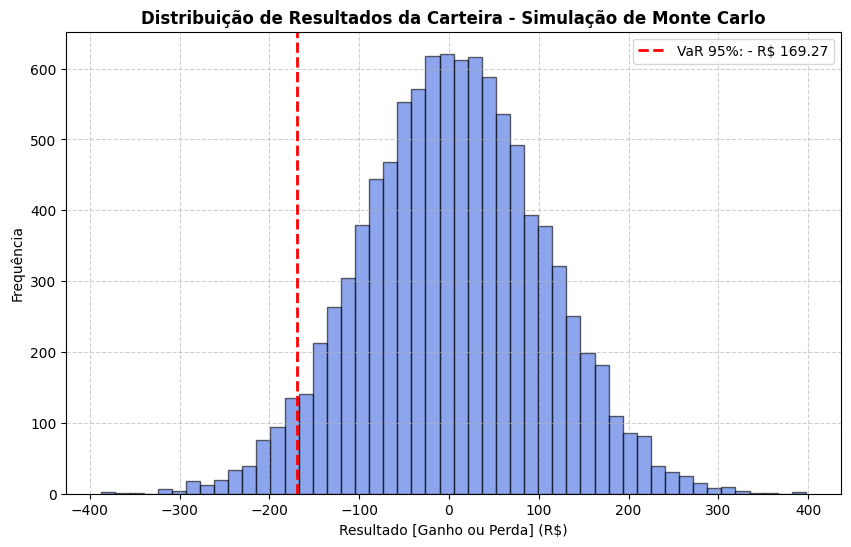

In [80]:
# -- Gráfico da distribuição das perdas simuladas incluindo VaR --
plt.figure(figsize=(10, 6))           # gera um figura de 10x6 pols
plt.hist(resultado, bins=50, alpha=0.6, color='royalblue', edgecolor='black')                 # cria um histograma de 50 barras com os resultados da carteira
plt.axvline(var_monte_carlo*(-1), color='red', linestyle='dashed', linewidth=2,               # gera uma linha vertical vermelha indicando o VaR
            label=f'VaR 95%: - R$ {var_monte_carlo:.2f}')
plt.title('Distribuição de Resultados da Carteira - Simulação de Monte Carlo', weight='bold') # título do gráfico
plt.xlabel('Resultado [Ganho ou Perda] (R$)')                                                 # título do eixo horizontal
plt.ylabel('Frequência')                                                                      # título do eixo vertical
plt.legend()                                                                                  # exibe legenda
plt.grid(True, linestyle='--', alpha=0.6)                                                     # exibe a grade
plt.show()                                                                                    # mostra a figura